# 03 · Comparação de modelos

O treino oficial é `uv run churn-train` (`src/churn/train.py`). Aqui analisamos os resultados registrados e o modelo campeão.

In [1]:
import json

import pandas as pd

from churn.config import CHAMPION_PATH, EXPERIMENTS_PATH

In [2]:
exp = pd.read_csv(EXPERIMENTS_PATH)
last_run = exp[exp['run_id'] == exp['run_id'].max()]
last_run.set_index('model').filter(like='_mean').round(4)

,cv_roc_auc_mean,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean
model,,,,,
logistic_regression,0.8460,0.6601,0.6282,0.8013,0.5169
random_forest,0.8448,0.6527,0.6308,0.7605,0.5392
mlp,0.8420,0.6472,0.5808,0.5217,0.6564


In [3]:
metadata = json.loads(CHAMPION_PATH.with_suffix('.json').read_text(encoding='utf-8'))
metadata

{'version': 'logistic_regression-20261103-091333',
 'model': 'logistic_regression',
 'threshold': 0.18,
 'seed': 42,
 'trained_at': '2026-11-03T09:14:33',
 'n_train': 5634,
 'n_test': 1409,
 'test_metrics': {'roc_auc': 0.8415,
  'pr_auc': 0.6325,
  'f1': 0.5486,
  'recall': 0.9733,
  'precision': 0.382,
  'business_cost': 57021.4,
  'business_cost_threshold_0_5': 86649.4,
  'business_cost_no_model': 326578.8}}

## Campeão no conjunto de teste

O mesmo split do `train.py`: mesma seed, estratificado, 20%. Matriz de confusão no threshold de custo, comparada com o threshold padrão de 0,5.

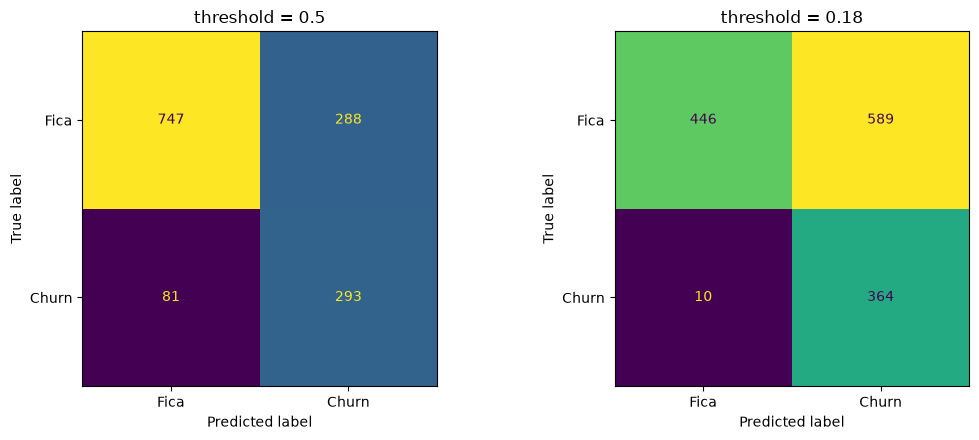

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score
from sklearn.model_selection import train_test_split

from churn.config import SEED, TEST_SIZE
from churn.data import load_dataset
from churn.predict import load_model

X, y = load_dataset()
_, X_test, _, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
model = load_model()
proba = pd.Series(model.pipeline.predict_proba(X_test)[:, 1], index=X_test.index)
y_pred = (proba >= model.threshold).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, model.threshold]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (proba >= t).astype(int), display_labels=['Fica', 'Churn'], ax=ax, colorbar=False
    )
    ax.set_title(f'threshold = {t}')
plt.tight_layout()

## Análise de vieses (para o Model Card)

Recall e precision do campeão no conjunto de teste, com o threshold de custo, por `gender` e `SeniorCitizen`.

In [5]:
rows = []
for col in ['gender', 'SeniorCitizen']:
    for value, ids in X_test.groupby(col).groups.items():
        yt, yp = y_test.loc[ids], y_pred.loc[ids]
        rows.append({
            'subgrupo': f'{col} = {value}',
            'n': len(ids),
            'taxa_churn_real': yt.mean(),
            'recall': recall_score(yt, yp),
            'precision': precision_score(yt, yp),
        })
pd.DataFrame(rows).round(3)

,subgrupo,n,taxa_churn_real,recall,precision
0,gender = Female,687,0.281,0.969,0.398
1,gender = Male,722,0.251,0.978,0.366
2,SeniorCitizen = 0,1187,0.233,0.967,0.350
3,SeniorCitizen = 1,222,0.441,0.990,0.511


## Conclusões

- **Comparação** (CV de 5 folds): os três modelos ficaram tecnicamente empatados.
  - Regressão Logística: ROC-AUC 0,846
  - Random Forest: ROC-AUC 0,845
  - MLP: ROC-AUC 0,842

  As diferenças ficam dentro de um desvio padrão.
- **Campeão: Regressão Logística.** Tem a maior ROC-AUC e PR-AUC, o melhor recall e é o modelo mais simples,
  rápido e interpretável. A Random Forest teve F1 levemente maior e a MLP a maior precision, mas nenhuma das
  duas justifica a complexidade extra.
- **Threshold de custo (0,18), no conjunto de teste:** recall de **97%**. A precision cai para 38%, mas,
  com as premissas de custo do projeto (R$ 50 por oferta contra 12 mensalidades por churn perdido),
  errar para mais compensa:

  | Política | Custo de negócio (teste) |
  |---|---|
  | Sem modelo | R$ 326,6 mil |
  | Threshold 0,5 | R$ 86,6 mil |
  | Threshold de custo (0,18) | **R$ 57,0 mil (−83%)** |

- **Vieses:**
  - **Por gênero:** recall e precision ficam a menos de 3 p.p. de distância entre os grupos.
  - **Idosos:** churn real de 44% contra 23%, e recebem proporcionalmente mais ofertas. Isso reflete o
    comportamento da base, mas a alocação das ofertas deve ser decidida pelo negócio. Detalhes no
    [Model Card](../docs/model_card.md).